Notebook para encontar minimos de las funciones de Rastriguin, Ackley, Rosenbrock, Lévy, Griewank, Easom y el camello de tres jorobas; usando los métodos de Newton y Broyden, así como las velocidades de convergencia de dichos métodos aplicados a cada función y para encontrar una "buena" vecindad donde el método de Newtón funcione bien.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

El $ϵ$ de la computadora

In [ ]:
eps = np.finfo(float).eps

In [ ]:
def zNewton(f, g, x0, itermax, tol):
    """
    Implementación del método de Newton.

    Parámetros:
        f       : Función f(x)
        g       : Derivada o matriz Jacobiana g(x)
        x0      : Valor inicial (escalar o vector NumPy)
        itermax : Número máximo de iteraciones
        tol     : Tolerancia

    Devuelve:
        xk      : Solución aproximada obtenida
        orbita  : Lista con la secuencia de iteraciones [x0, x1, ...]
        error   : Norma de la última diferencia
    """
    #x0 = np.asarray(x0,dtype=float)
    flag = True
    orbita = [x0.copy() if x0.ndim > 0 else float(x0)]
    iter_count = 1

    xk = x0
    error = 0.0

    while flag and iter_count < itermax:
        fx = f(x0) #np.asarray(f(x0),dtype=float)
        gx = g(x0) #np.asarray(g(x0),dtype=float)

        # Cálculo del paso sk = -g(x0) \ f(x0)
        if gx.ndim == 0 or gx.size == 1:
            sk = -fx / gx
        else:
            sk = np.linalg.solve(gx, -fx)

        xk = x0 + sk
        error = float(np.linalg.norm(xk - x0))

        norm_x0 = float(np.linalg.norm(x0))
        if error < tol * norm_x0:
            flag = False  # Salida por criterio de paro

        orbita.append(xk.copy() if np.ndim(xk) > 0 else float(xk))
        iter_count += 1
        x0 = xk

    return xk, orbita, error

In [ ]:
def broyden(f, x0, itermax, tol):
    """
    Implementación del método de Broyden.

    Parámetros:
      f       : función vectorial que recibe un array 1D y retorna un array 1D
      x0      : punto inicial (lista o array de NumPy)
      itermax : número máximo de iteraciones
      tol     : tolerancia de convergencia

    Retorna:
      xk      : solución aproximada
      orbita  : historial de puntos calculados
      error   : norma de la última diferencia entre iteraciones
    """
    x0 = np.array(x0, dtype=float)
    n = len(x0)

    if np.linalg.norm(f(x0)) > tol:
        flag = 1
    else:
        flag = 0

    # Inicialización
    flag = 1
    orbita = [x0.copy()]
    iter_cnt = 1
    Bk = np.eye(n)

    xk = x0.copy()
    error = 0.0

    while flag and iter_cnt < itermax:
        fx0 = f(x0)

        # Cálculo del paso (equivalente a -Bk \ f(x0) en MATLAB)
        sk = np.linalg.solve(Bk, -fx0)
        alpha = 1.0

        # Comentario original del cálculo de paso armijo (opcional):
        # while np.linalg.norm(f(x0 + alpha * sk)) > np.linalg.norm(f(x0)):
        #     alpha /= 2.0

        xk = x0 + alpha * sk
        yk = f(xk) - fx0

        # Actualización de la aproximación al jacobiano/gradiente mediante producto exterior
        Bk = Bk + np.outer(yk - Bk @ sk, sk) / np.dot(sk, sk)

        error = np.linalg.norm(xk - x0)
        if error < (np.linalg.norm(x0) + 1) * tol:
            flag = 0  # Condición de salida

        orbita.append(xk.copy())
        iter_cnt += 1
        x0 = xk.copy()

    return xk, np.array(orbita), error

Rastring:
$f(x,y)=20+x^2+y^2 -10\cos(2\pi x)-10\cos(2\pi y)$



In [ ]:
gradf_ras = lambda X: np.array([2*X[0] + 20*np.pi*np.sin(2*np.pi*X[0]),
                                2*X[1] + 20*np.pi*np.sin(2*np.pi*X[1])])
hessf_ras = lambda X: np.array([
                                [2 + 40*np.pi**2*np.cos(2*np.pi*X[0]), 0],
                                [0, 2 + 40*np.pi**2*np.cos(2*np.pi*X[1])]
                              ])

Ackley:
$f(x,y)=-20\exp{(
-0.2\sqrt{\frac{x^2+y^2}{2}})}-\exp{(
\frac{\cos(2\pi x)+\cos(2\pi y)}{2})}+20+e$

Importante: ajuste su gradiente y hessiana sumando $ϵ$ en dónde habria una división por 0, pues esta función no es diferenciable en $(0,0)$  


In [ ]:
gradf_acl = lambda X: np.array([
2*X[0]*np.exp(-0.2*np.sqrt((X[0]**2 + X[1]**2)/2))/np.sqrt((X[0]**2 + X[1]**2)/2 + eps) + np.pi*np.exp((np.cos(2*np.pi*X[0]) + np.cos(2*np.pi*X[1]))/2)*np.sin(2*np.pi*X[0]),
2*X[1]*np.exp(-0.2*np.sqrt((X[0]**2 + X[1]**2)/2))/np.sqrt((X[0]**2 + X[1]**2)/2 + eps) + np.pi*np.exp((np.cos(2*np.pi*X[0]) + np.cos(2*np.pi*X[1]))/2)*np.sin(2*np.pi*X[1])])

hessf_acl = lambda X: np.array([
[2*np.exp(-0.2*np.sqrt((X[0]**2 + X[1]**2)/2))*(1/np.sqrt((X[0]**2 + X[1]**2)/2 + eps) - X[0]**2/(2*((X[0]**2 + X[1]**2)/2 + eps)**(3/2)) - 0.2*X[0]**2/(2*((X[0]**2 + X[1]**2)/2 + eps))) + np.pi**2*np.exp((np.cos(2*np.pi*X[0]) + np.cos(2*np.pi*X[1]))/2)*(2*np.cos(2*np.pi*X[0]) - np.sin(2*np.pi*X[0])**2),
  -np.exp(-0.2*np.sqrt((X[0]**2 + X[1]**2)/2))*X[0]*X[1]/(2*((X[0]**2 + X[1]**2)/2 + eps)**(3/2)) + np.pi**2*np.exp((np.cos(2*np.pi*X[0]) + np.cos(2*np.pi*X[1]))/2)*(-np.sin(2*np.pi*X[0])*np.sin(2*np.pi*X[1]))],
[ -np.exp(-0.2*np.sqrt((X[0]**2 + X[1]**2)/2))*X[0]*X[1]/(2*((X[0]**2 + X[1]**2)/2 + eps)**(3/2)) + np.pi**2*np.exp((np.cos(2*np.pi*X[0]) + np.cos(2*np.pi*X[1]))/2)*(-np.sin(2*np.pi*X[0])*np.sin(2*np.pi*X[1])),
 2*np.exp(-0.2*np.sqrt((X[0]**2 + X[1]**2)/2))*(1/np.sqrt((X[0]**2 + X[1]**2)/2 + eps) - X[1]**2/(2*((X[0]**2 + X[1]**2)/2 + eps)**(3/2)) - 0.2*X[1]**2/(2*((X[0]**2 + X[1]**2)/2 + eps))) + np.pi**2*np.exp((np.cos(2*np.pi*X[0]) + np.cos(2*np.pi*X[1]))/2)*(2*np.cos(2*np.pi*X[1]) - np.sin(2*np.pi*X[1])**2)]
])


Rosenbrock:
$f(x,y)=100(y-x^2)^2+(1-x)^2$


In [ ]:
gradf_ros = lambda X: np.array([-400*X[0]*(X[1] - X[0]**2) - 2*(1 - X[0]),
                                200*(X[1] - X[0]**2)])
hessf_ros = lambda X: np.array([
                                [1200*X[0]**2 - 400*X[1] + 2, -400*X[0]],
                                [-400*X[0], 200]
                              ])

Lévy:
$
f(x,y)=\sin^2(3\pi x)+(x-1)^2 (1+\sin^2(3\pi y))+(y-1)^2(1+\sin^2(2\pi y))
$

In [ ]:
gradf_lev = lambda X: np.array([3*np.pi*np.sin(6*np.pi*X[0]) + 2*(X[0] - 1)*(1 + np.sin(3*np.pi*X[1])**2),
                                3*np.pi*(X[0] - 1)**2*np.sin(6*np.pi*X[1]) + 2*(X[1] - 1)*(1 + np.sin(2*np.pi*X[1])**2) + 2*np.pi*(X[1] - 1)**2*np.sin(4*np.pi*X[1])])
hessf_lev = lambda X: np.array([
                                [18*np.pi**2*np.cos(6*np.pi*X[0]) + 2*(1 + np.sin(3*np.pi*X[1])**2),
                                 6*np.pi*(X[0] - 1)*np.sin(6*np.pi*X[1])],
                                [6*np.pi*(X[0] - 1)*np.sin(6*np.pi*X[1]),
                                 18*np.pi**2*(X[0] - 1)**2*np.cos(6*np.pi*X[1]) + 2*(1 + np.sin(2*np.pi*X[1])**2) + 8*np.pi*(X[1] - 1)*np.sin(4*np.pi*X[1]) + 8*np.pi**2*(X[1] - 1)**2*np.cos(4*np.pi*X[1])]
                              ])

Griewank:
$
f(x,y)=1+\frac{x^2+y^2}{4000}
-\cos(x)\cos\left(\frac{y}{\sqrt{2}}\right)
$

In [ ]:
gradf_gri = lambda X:  np.array([X[0]/2000 + np.sin(X[0])*np.cos(X[1]/np.sqrt(2)),
                                 X[1]/2000 + np.cos(X[0])*np.sin(X[1]/np.sqrt(2))/np.sqrt(2)])
hessf_gri = lambda X: np.array([
                                [1/2000 + np.cos(X[0])*np.cos(X[1]/np.sqrt(2)),
                                 -np.sin(X[0])*np.sin(X[1]/np.sqrt(2))/np.sqrt(2)],
                                [-np.sin(X[0])*np.sin(X[1]/np.sqrt(2))/np.sqrt(2),
                                 1/2000 + np.cos(X[0])*np.cos(X[1]/np.sqrt(2))/2]
                              ])


Easom:
$
f(x,y)=-\cos(x)\cos(y)
\exp\left(- (x-\pi)^2-(y-\pi)^2\right)
$

In [ ]:
gradf_eas = lambda X: np.array([np.exp(-(X[0] - np.pi)**2 - (X[1] - np.pi)**2)*np.cos(X[1])*(np.sin(X[0]) + 2*(X[0] - np.pi)*np.cos(X[0])),
                                np.exp(-(X[0] - np.pi)**2 - (X[1] - np.pi)**2)*np.cos(X[0])*(np.sin(X[1]) + 2*(X[1] - np.pi)*np.cos(X[1]))])
hessf_eas = lambda X: np.array([
[ np.exp(-(X[0]-np.pi)**2 - (X[1]-np.pi)**2)*np.cos(X[1])*((3 - 4*(X[0]-np.pi)**2)*np.cos(X[0]) - 4*(X[0]-np.pi)*np.sin(X[0])),
 -np.exp(-(X[0]-np.pi)**2 - (X[1]-np.pi)**2)*(np.sin(X[0]) + 2*(X[0]-np.pi)*np.cos(X[0]))*(np.sin(X[1]) + 2*(X[1]-np.pi)*np.cos(X[1]))],
[-np.exp(-(X[0]-np.pi)**2 - (X[1]-np.pi)**2)*(np.sin(X[0]) + 2*(X[0]-np.pi)*np.cos(X[0]))*(np.sin(X[1]) + 2*(X[1]-np.pi)*np.cos(X[1])),
  np.exp(-(X[0]-np.pi)**2 - (X[1]-np.pi)**2)*np.cos(X[0])*((3 - 4*(X[1]-np.pi)**2)*np.cos(X[1]) - 4*(X[1]-np.pi)*np.sin(X[1]))]
])

Camello:
$
f(x,y)=2x^2-1.05x^4+\frac{x^6}{6}+xy+y^2
$

In [ ]:
gradf_cam = lambda X: np.array([4*X[0] - 4.2*X[0]**3 + X[0]**5 + X[1], X[0] + 2*X[1]])
hessf_cam = lambda X: np.array([
                                [4 - 12.6*X[0]**2 + 5*X[0]**4, 1],
                                [1, 2]
                              ])

Grad guarda los gradientes de cada función,
Hess guarda las matrices hessianas de cada función, además la longitud de cada uno nos dice el número de funciones en el código.

BMINs y BORBs, guardaran el minimo calculado de cada función y todas las aproximaciones en cada iteración con el método de Broyden, respectvamente, lo mismo con NMINs y NORBs, respectivamente.

In [ ]:
Grad = [gradf_ras,gradf_acl,gradf_ros,gradf_lev,gradf_gri,gradf_eas,gradf_cam]
Hess = [hessf_ras,hessf_acl,hessf_ros,hessf_lev,hessf_gri,hessf_eas,hessf_cam]

BMINs = [None] * len(Grad)
BORBs = [None] * len(Grad)
NMINs = [None] * len(Grad)
NORBs = [None] * len(Grad)

Parametros:
$kmax, tol$ son los mismos para todas las funciones, mientras que $x_0$ cambia para cada una de ellas (y se especifican en la lista X0)

In [ ]:
X0 = [np.array([.2, .2]),
      np.array([.5, .5]),
      np.array([-1.2, 1.0]),
      np.array([1.5, 1.5]),
      np.array([.5, .5]),
      np.array([3., 3.]),
      np.array([.5, .5])]
kmax = 1e3
tol = 1.e-9

Aquí se llama a las funciones de zNewton y Broyden para que encuentren los ceros del gradiente de cada función. Luego se verifica si efectivamnete dichos ceros son minimos, esto se hace verificando si todos los valores propios de la hessiana de cada función evaluada en los ceros calculados son positivos. Como las funciones son de dos variables, es facil establecer el criterio que aparece en el código para verificar eso.

  Cada minimo se almacena en los arreglos mencionados en la celda anterior, además identificamos a la funciones con indices de acuerdo al orden en el que aparecen en el código:


0.-Rastriguin,


1.-Ackley,

..., etc.

In [ ]:
for i in range(len(Grad)):
  xN,_,_ = zNewton(Grad[i],Hess[i],X0[i],kmax,tol)
  xB,_,_ = broyden(Grad[i],X0[i],kmax,tol)
  VN = np.linalg.eigvals(Hess[i](xN))
  VB = np.linalg.eigvals(Hess[i](xB))
  if (VN[0] > 0 and VN[0]*VN[1] > 0):
    NMINs[i],NORBs[i],_= zNewton(Grad[i],Hess[i],X0[i],kmax,tol)
  else:
    "No es minimo, N"
  if (VB[0] > 0 and VB[0]*VN[1] > 0):
    BMINs[i],BORBs[i],_= broyden(Grad[i],X0[i],kmax,tol)
  else:
    "No es minimo, B"


Se crean dos listas: NERRs,BERRs, las cuales contienen la norma de los errores en cada iteración (menos la ultima)

In [ ]:
NE = [None] * len(Grad)
BE = [None] * len(Grad)
NERRs = [None] * len(Grad)
BERRs = [None] * len(Grad)

for i in range(len(Grad)):
  NE[i] = NORBs[i][:-1] - NMINs[i]
  BE[i] = BORBs[i][:-1] - BMINs[i]

for i in range(len(Grad)):
  NERRs[i] = []
  BERRs[i] = []
  for j in range(len(NE[i])):
    NERRs[i].append(float(np.linalg.norm(NE[i][j])))
  for k in range(len(BE[i])):
    BERRs[i].append(float(np.linalg.norm(BE[i][k])))

print(NERRs[0])

[1.689926711842809, 1.0038157603536983, 0.03185535820336242, 0.00014126222020761277, 1.4160224258980536e-09, 1.5700924586837752e-16]


In [ ]:
m,_ = np.polyfit(np.log([0.0091540219485845, 3.066576373702163e-06,]),np.log([3.066576373702163e-06, 1.3214458407973176e-12]),1)
print(m)

1.831850663080718


Aquí se filtran las listas de la celda anterior quitandoles sus elementos pequeños (para no generar problemas con el logaritmo). Luego se crean los datos $(ln(e^{k}),ln(e^{k+1}))$, procurando que para cada método y para cada función sean solo los ultimos 5 puntos; si es que hay al menos 6 elementos en la listas con las normas de los errores, si no pues se toman todos los elementos para construir esos puntos. Con eso es posible obtener el ajuste lineal que mejor aproxima los puntos y con ellos la velocidad de convergencia (la pendiente de dicho ajuste). Si es que el método no convergió, se avisa, pues en esos casos un ajuste lineal no dice nada, pues los datos simplemente no tienen una tendencia definida.


In [ ]:
NX = [None]*len(Grad)
NY = [None]*len(Grad)
Np = [None]*len(Grad)
BX = [None]*len(Grad)
BY = [None]*len(Grad)
Bp = [None]*len(Grad)

for i in range (len(Grad)):
  errN = np.array(NERRs[i])
  errN = errN[errN > eps]
  errB = np.array(BERRs[i])
  errB = errB[errB > eps]
  if (len(errN) >= 6 and len(NORBs[i]) < kmax):
     NX[i] = np.log(errN[-6:][:5])
     NY[i] = np.log(errN[-6:][-5:])
     Np[i],_ = np.polyfit(NX[i],NY[i],1)
  elif (len(errN) < 6):
     NX[i] = np.log(errN[:len(errN)-1])
     NY[i] = np.log(errN[-len(errN)+1:])
     Np[i],_ = np.polyfit(NX[i],NY[i],1)
  elif (len(NORBs[i]) == kmax):
    Np[i] = "No convergió"
  if (len(errB) >= 6 and len(BORBs[i]) < kmax):
     BX[i] = np.log(errB[-6:][:5])
     BY[i] = np.log(errB[-6:][-5:])
     Bp[i],_ = np.polyfit(BX[i],BY[i],1)
  elif (len(errB) < 6):
     BX[i] = np.log(errB[:len(errB)-1])
     BY[i] = np.log(errB[-len(errB)+1:])
     Bp[i],_ = np.polyfit(BX[i],BY[i],1)
  elif (len(BORBs[i]) == kmax):
    Bp[i] = "No convergió"

#    print(len(Neant[i]))
#    print(Neant[i])

[28.928911231857732, 38.9315307135418, 14.139134284407193, 54.12721419109975, 29.039926749854057, 38.62251100506031, 23.260973648279382, 24.795935998306526, 16.123370783797384, 13.205109663327885, 11.606119446887988, 20.81752436449295, 101.847405708759, 391.12644525065895, 119.62689306821021, 80.13970129539075, 210.83839889596157, 15.172672185449917, 14.621651754315092, 12.570663239355897, 1409.1266115680476, 39.28354809016586, 48.081126339541626, 39.46769962515549, 40.082407816206654, 39.18238497988799, 38.92519402985389, 39.78473148683969, 39.6376206837626, 39.57422384344388, 39.802623481510224, 43.15127136189864, 46.081258404836554, 43.811269013268635, 213.155608960199, 59.509967339627714, 17.913752911558472, 2.248209151076971, 5.578885302329849, 2.096801341286482, 1.4772121214827936, 2.636650155559396, 2.9050089520324596, 1.1380083846094664, 0.7739219306249475, 1.577745655651277, 0.07891681189387212, 0.23759268887371027, 0.020830648268170635, 0.007601045701655489, 0.001911360498348

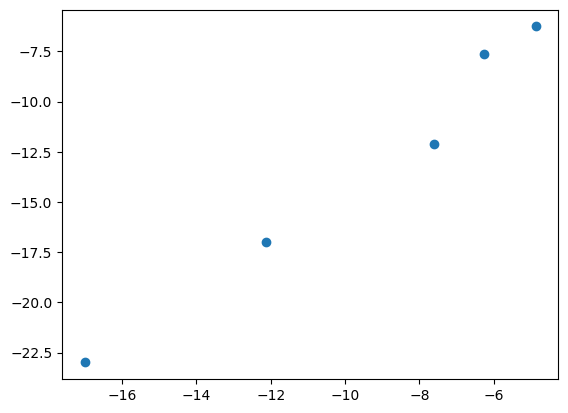

In [ ]:
print(BERRs[0])

plt.plot(BX[0],BY[0],'o')

Se imprimen las velocidades de convergencia de cada método para cada función.

In [ ]:
for i in range(len(Grad)):
   print("La función con indice",i, ", tiene velocidad de convergencia de:")
   print(Np[i],"con Newton, y de",Bp[i], "con Broyden")

La función con indice 0 , tiene velocidad de convergencia de:
2.050518988185912 con Newton, y de 1.3768617676286397 con Broyden
La función con indice 1 , tiene velocidad de convergencia de:
1.0308608759097864 con Newton, y de 1.4465234549207926 con Broyden
La función con indice 2 , tiene velocidad de convergencia de:
1.9867683258189701 con Newton, y de No convergió con Broyden
La función con indice 3 , tiene velocidad de convergencia de:
1.8234618277698127 con Newton, y de -139490799616.0219 con Broyden
La función con indice 4 , tiene velocidad de convergencia de:
3.0807498477628132 con Newton, y de 1.434938184372603 con Broyden
La función con indice 5 , tiene velocidad de convergencia de:
3.011651276129902 con Newton, y de 1.7987511765665474 con Broyden
La función con indice 6 , tiene velocidad de convergencia de:
1.9782728678126398 con Newton, y de 1.12429885169721 con Broyden


Notamos que para Ackley, el método de Newtón se comporta de forma lineal, esto es por sumar la variable $\epsilon$ dentro de su gradiente y matriz hessiana.


También notamos que con $x_0=(-1.2,1.0)$ el método de Broyden falló para la función de Rosenbrock. Por otro lado para el caso de la función de Lévy con el método de Broyden se obtiene una pendiente extremadamente pronunciada, esto porque el método superó muy rapidamente a la tolerancia y los valores de las normas de los errores dierón un salto gigantesco (se puede observar al imprimir BEERs[3]).

Además para el caso de las funciones de Griewank y Easom Newton fue mucho mas que cúadratico, presentó una convergencia cúbica.

Fuera de eso, vemos que los métodos de Newtón y Broyden presentan convergencia cúadratica y superlineal, como dicta la teoría.

Para estimar el radio $r$ de $B_r(x^*)$, donde el método de Newton se comporta "bien" y donde $x^*$ es el mínimo cálculado con la función *zNewton* se prueba con varios radios y varios ángulos, es decir para cada radio r' dentro de cierto dominio discreto (en este caso la partición del intervalo del intervalo $[0.01,2]$ en 100 puntos x-espaciados) se toma un punto $x_{temp}$ de la $Fr(B_{r'}(x^*))$ y se usa como aproximación inicial para la función *ZNewton* con los mismos parametros de antes, la cual, devuelve un punto crítico $x_k$, se checa que sea mínimo y luego se verifica si es que $||x_k-x^*||_2\leq\sqrt{tol}$. Si es que para algún $r'$ sucede que $||x_k-x^*||_2\ > \sqrt{tol}$, entonces se elige al $r'$ anterior a él como un posible radio satisfactorio. En este caso, el proceso se repite cuatro veces, para cada función, escogiendo en cada caso a $x_{temp}$ paralelo a $\hat{\imath}_{x^*}$ o a $\hat{\jmath}_{x^*}$, haciendo enfasis que son los vectores unitarios pensando a $x^*$ como si fuera el origen. Una vez optenidos los cuatro puntos, se escoge al minimo de ellos y ese es el valor $r$ buscado.

In [ ]:
rmax = 2.
pasos = 100
Rs = np.linspace(.01, rmax, pasos)
Angs = [0., np.pi/2, np.pi, 3*np.pi/2]

R = [None]*len(Grad)
for i in range(len(Grad)):
  pr = [None]*4
  for a,k in zip(Angs,range(4)):
    j = 0
    for r in Rs:
      xtemp = NMINs[i] + r*np.array([np.cos(a), np.sin(a)])
      xk,_,_ = zNewton(Grad[i],Hess[i],xtemp,kmax,tol)
      V = np.linalg.eigvals(Hess[i](xk))
      if (VN[0] > 0 and VN[0]*VN[1] > 0)
        if (np.linalg.norm(xk-NMINs[i]) <= np.sqrt(tol)):
          j = j + 1
        else:
          break
    pr[k] = float(Rs[j-1])
  R[i] = np.min(pr)



In [ ]:
for i in range(len(Grad)):
  print("Una buena vecindad para el método de Newtón para la función con indice ",i," al rededor del minimo: " ,NMINs[i])
  print("Tiene radio: ",R[i])

Una buena vecindad para el método de Newtón para la función con indice  0  al rededor del minimo:  [-0.99495864 -0.99495864]
Tiene radio:  0.17080808080808083
Una buena vecindad para el método de Newtón para la función con indice  1  al rededor del minimo:  [1.59502892 0.94589849]
Tiene radio:  0.0904040404040404
Una buena vecindad para el método de Newtón para la función con indice  2  al rededor del minimo:  [1. 1.]
Tiene radio:  2.0
Una buena vecindad para el método de Newtón para la función con indice  3  al rededor del minimo:  [1.50570416 1.        ]
Tiene radio:  0.050202020202020206
Una buena vecindad para el método de Newtón para la función con indice  4  al rededor del minimo:  [0. 0.]
Tiene radio:  1.1557575757575758
Una buena vecindad para el método de Newtón para la función con indice  5  al rededor del minimo:  [3.14159265 3.14159265]
Tiene radio:  0.41202020202020206
Una buena vecindad para el método de Newtón para la función con indice  6  al rededor del minimo:  [ 1.74

Notamos que la función de Rosenbrock alcanzó el radio máximo posible, es decir el método de Newtón se comporta "bien" para vecindades "grandes".

El resultado de las funciones de Rastrigin, Easom, Lévy (la cual obtuvo el menor radio) es de esperarse pues son funciones que incluyen funciones periodicas, lo que hace que tengan muchisimos mínimos repartidos uniformemente. Lo mismo pasa con la función de Ackley, además, como el radio se calculó para un mínimo que no es el mínimo global, entonces tiene muy poco margen el método de Newton para no "salirse" de ese mínimo.

Por último notamos que apesar de que la función de Griewank tiene un coseno en su expresión y por ende tiene infinitos mínimos repartidos en todo el plano, su radio "bueno" al rededor de su mínimo $(3.14159265 3.14159265)$, es mayor que el de la función del camello de tres jorobas al rededor del mínimo local $(1.74755235 -0.87377617)$, apesar de que este solo tiene tres mínimos. Esto es por el hecho de comparar la vecindad buena de un mínimo global, con la de un mínimo local.